## Machine Learning Mini-Project (Phase 1 & Phase 2)
### **Team Members**:- Vishal Shinde(251090700194) And Sumit Patil(251090700100) 
### MCA - A 
### Batch - A2 

---

## **Dataset And Overview:-**
#### **Dataset**:- Chronic Kidney Disease Dataset 
#### **Link Of Dataset** :- https://www.kaggle.com/datasets/rabieelkharoua/chronic-kidney-disease-dataset-analysis

### **Problem Statement**
#### Develop and evaluate machine learning approaches that classify the dataset's 'Diagnosis' label from selected patient and laboratory features. The label's clinical meaning must be confirmed from the dataset documentation before interpreting it as Chronic Kidney Disease.

### **Objectives**
#### 1.) Inspect the dataset metadata and data quality.
#### 2.)  Explore target distribution, feature statistics, missingness, correlations and possible outliers.
#### 3.)  Selecting set of all 51 input features for a report upload plus questionnaire workflow.
#### 4.)  Shortlisted six models for Phase 2 including at least two ensemble models.

### Six Final Models Included
1. **Model 1:** Logistic Regression
2. **Model 2:** Support Vector Machine (SVM)
3. **Model 3:** Multilayer Perceptron (MLP Neural Network)
4. **Model 4:** Gaussian Naive Bayes (GaussianNB)
5. **Model 5:** Random Forest Classifier (Ensemble Model 1)
6. **Model 6:** Gradient Boosting Classifier (Ensemble Model 2)

---
## 2. Loading the Dataset

### Explanation
- **What are we doing?** We import basic Python libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load `Chronic_Kidney_Dsease_data.csv`.
- **Why are we doing it?** To read the raw patient records from our project folder into a Pandas DataFrame so we can inspect and work with the data.
- **What does the code do?** It imports the required libraries, reads the CSV file using `pd.read_csv()`, and prints the dimensions (rows and columns).
- **How to understand the output?** You will see the total number of patients (rows) and attributes (columns).

In [1]:
# Essential Imports:- 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib     
import time
import warnings
# Warnings are left visible during validation so convergence or other useful warnings are not hidden.    
# Controls warning messages displayed during execution, allowing you to ignore unnecessary warnings.


# Scikit-Learn Preprocessing & Model Selection:- 

from sklearn.model_selection import(
train_test_split, 
StratifiedKFold, 
# Splits data into folds while maintaining class proportions for reliable model evaluation.
cross_val_score)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer    
# Fills missing values using values from the nearest, most similar data points.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 4 Normal Models:- 

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB


# 2 Ensemble Models:- 

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Evaluation Metrics:- 

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    balanced_accuracy_score, precision_recall_curve, auc
)

In [2]:
# Dataset And Metadata

df = pd.read_csv('Chronic_Kidney_Dsease_data.csv')
df.head()

df.info()
display(df.describe())
display(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 1659 entries, 0 to 1658
Data columns (total 54 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PatientID                      1659 non-null   int64  
 1   Age                            1659 non-null   int64  
 2   Gender                         1659 non-null   int64  
 3   Ethnicity                      1659 non-null   int64  
 4   SocioeconomicStatus            1659 non-null   int64  
 5   EducationLevel                 1659 non-null   int64  
 6   BMI                            1659 non-null   float64
 7   Smoking                        1659 non-null   int64  
 8   AlcoholConsumption             1659 non-null   float64
 9   PhysicalActivity               1659 non-null   float64
 10  DietQuality                    1659 non-null   float64
 11  SleepQuality                   1659 non-null   float64
 12  FamilyHistoryKidneyDisease     1659 non-null   int64  
 13 

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,MuscleCramps,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis
count,1659.000000,1659.000000,1659.000000,1659.00000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,...,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000
mean,830.000000,54.441230,0.515371,0.71308,0.977697,1.693189,27.620049,0.292948,9.969831,5.024247,...,3.525510,5.054869,49.730659,0.044002,0.103074,0.197107,2.000336,4.947788,5.144973,0.918626
std,479.056364,20.549757,0.499914,1.00043,0.776686,0.910611,7.288670,0.455252,5.798787,2.866274,...,2.026131,2.880460,27.827593,0.205162,0.304147,0.397934,1.141635,2.869959,2.901138,0.273492
min,1.000000,20.000000,0.000000,0.00000,0.000000,0.000000,15.033888,0.000000,0.021740,0.001186,...,0.006327,0.013697,0.087256,0.000000,0.000000,0.000000,0.001082,0.005392,0.004436,0.000000
25%,415.500000,36.000000,0.000000,0.00000,0.000000,1.000000,21.471449,0.000000,5.051156,2.555038,...,1.820793,2.532867,26.991708,0.000000,0.000000,0.000000,1.005802,2.498119,2.569561,1.000000
50%,830.000000,54.000000,1.000000,0.00000,1.000000,2.000000,27.652077,0.000000,9.951503,5.072395,...,3.572522,5.087086,48.970075,0.000000,0.000000,0.000000,2.040635,4.974069,5.182949,1.000000
75%,1244.500000,72.000000,1.000000,1.00000,2.000000,2.000000,34.015849,1.000000,14.967100,7.460563,...,5.254956,7.552093,73.913997,0.000000,0.000000,0.000000,2.947213,7.499783,7.733253,1.000000
max,1659.000000,90.000000,1.000000,3.00000,2.000000,3.000000,39.993532,1.000000,19.992713,9.998167,...,6.984636,9.998313,99.987510,1.000000,1.000000,1.000000,3.999469,9.992345,9.993754,1.000000


(1659, 54)

---
## 4. Dataset Metadata and Initial Inspection

### Explanation
- **What does the code do?** Uses `df.head()`, `df.tail()`, `df.info()`, and `df.describe()`.

In [3]:
print('DATASET METADATA SUMMARY')
print('-'*65)
print("Total Rows (Patients) = ",df.shape[0])
print("Total Columns = ", df.shape[1]," (51 X Features + 2 IDs + 1 Target Y)")
print("Total Missing Values = ", df.isnull().sum().sum())
print("Duplicate Rows = ", df.duplicated().sum())
print('\nData Types Breakdown:')
print(df.dtypes.value_counts())

print('\nTarget Variable (Diagnosis) Distribution:')
target_counts = df['Diagnosis'].value_counts()
target_pct = (df['Diagnosis'].value_counts(normalize=True) * 100).round(2)
metadata_target = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
metadata_target.index = ['1 (CKD Positive)', '0 (No CKD)']
display(metadata_target)

DATASET METADATA SUMMARY
-----------------------------------------------------------------
Total Rows (Patients) =  1659
Total Columns =  54  (51 X Features + 2 IDs + 1 Target Y)
Total Missing Values =  0
Duplicate Rows =  0

Data Types Breakdown:
float64    30
int64      23
str         1
Name: count, dtype: int64

Target Variable (Diagnosis) Distribution:


,Count,Percentage (%)
1 (CKD Positive),1524,91.86
0 (No CKD),135,8.14


In [4]:
# Check column data types and non-null counts
print("--- COLUMN DATA TYPES AND MEMORY USAGE ---")
df.info()

--- COLUMN DATA TYPES AND MEMORY USAGE ---
<class 'pandas.DataFrame'>
RangeIndex: 1659 entries, 0 to 1658
Data columns (total 54 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PatientID                      1659 non-null   int64  
 1   Age                            1659 non-null   int64  
 2   Gender                         1659 non-null   int64  
 3   Ethnicity                      1659 non-null   int64  
 4   SocioeconomicStatus            1659 non-null   int64  
 5   EducationLevel                 1659 non-null   int64  
 6   BMI                            1659 non-null   float64
 7   Smoking                        1659 non-null   int64  
 8   AlcoholConsumption             1659 non-null   float64
 9   PhysicalActivity               1659 non-null   float64
 10  DietQuality                    1659 non-null   float64
 11  SleepQuality                   1659 non-null   float64
 12  FamilyHistoryKid

In [5]:
# View summary statistics for numerical columns (mean, min, max, quartiles)
print("--- SUMMARY STATISTICS ---")
df.describe().T.head(15)  # Showing the first 15 columns for readability

--- SUMMARY STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
PatientID,1659.0,830.000000,479.056364,1.000000,415.500000,830.000000,1244.500000,1659.000000
Age,1659.0,54.441230,20.549757,20.000000,36.000000,54.000000,72.000000,90.000000
Gender,1659.0,0.515371,0.499914,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,1659.0,0.713080,1.000430,0.000000,0.000000,0.000000,1.000000,3.000000
SocioeconomicStatus,1659.0,0.977697,0.776686,0.000000,0.000000,1.000000,2.000000,2.000000
EducationLevel,1659.0,1.693189,0.910611,0.000000,1.000000,2.000000,2.000000,3.000000
BMI,1659.0,27.620049,7.288670,15.033888,21.471449,27.652077,34.015849,39.993532
Smoking,1659.0,0.292948,0.455252,0.000000,0.000000,0.000000,1.000000,1.000000
AlcoholConsumption,1659.0,9.969831,5.798787,0.021740,5.051156,9.951503,14.967100,19.992713
PhysicalActivity,1659.0,5.024247,2.866274,0.001186,2.555038,5.072395,7.460563,9.998167


---
## 5. Missing Values, Duplicates, and Target Column Inspection

### Explanation
- **What are we doing?** We check for any missing (`NaN`) values, duplicate rows, constant columns, and look at the target column `Diagnosis`.
- **Why are we doing it?** 
  1. Missing values can cause errors in algorithms if not handled.
  2. Duplicate rows might bias our evaluation.
  3. Columns with only 1 unique value contain no useful information.
  4. The target column tells us what we are predicting and whether our classes are balanced or imbalanced.

In [6]:
# Check for missing values across all columns
missing_values = df.isnull().sum()
total_missing = missing_values.sum()
print("Total missing values in dataset:", total_missing)

# Check for duplicate rows
duplicate_count = df.duplicated().sum()
print("Total duplicate rows:", duplicate_count)

# Check for constant columns (columns where every row has the exact same value)
constant_columns = [col for col in df.columns if df[col].nunique() == 1]
print("Constant columns (zero variance):", constant_columns)
for col in constant_columns:
    print(f"  -> Column '{col}' unique value:", df[col].unique())

# Check for unique identifier columns
id_columns = [col for col in df.columns if df[col].nunique() == len(df)]
print("Unique identifier columns:", id_columns)

Total missing values in dataset: 0
Total duplicate rows: 0
Constant columns (zero variance): ['DoctorInCharge']
  -> Column 'DoctorInCharge' unique value: <ArrowStringArray>
['Confidential']
Length: 1, dtype: str
Unique identifier columns: ['PatientID', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'NSAIDsUse', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore', 'MedicalCheckupsFrequency', 'MedicationAdherence', 'HealthLiteracy']


In [7]:
# Inspect the Target Column: 'Diagnosis'
print("--- TARGET COLUMN DISTRIBUTION ---")
target_counts = df['Diagnosis'].value_counts()
target_percentages = df['Diagnosis'].value_counts(normalize=True) * 100

# Put into a small readable table
target_summary = pd.DataFrame({
    'Diagnosis Class': target_counts.index,
    'Condition': ['Confirmed CKD (Class 1)', 'No CKD (Class 0)'],
    'Number of Patients': target_counts.values,
    'Percentage (%)': target_percentages.values.round(2)
})
target_summary

--- TARGET COLUMN DISTRIBUTION ---


,Diagnosis Class,Condition,Number of Patients,Percentage (%)
0,1,Confirmed CKD (Class 1),1524,91.86
1,0,No CKD (Class 0),135,8.14


### Interpretation of Target Distribution
- **Class 1 (CKD):** 1,524 patients (**91.86%**)
- **Class 0 (No CKD):** 135 patients (**8.14%**)

> **Key Observation for Viva/Presentation:**  
> The dataset has **class imbalance** because over 91% of patients have CKD.  
> If a model simply predicted "CKD" for everyone, it would achieve 91.86% accuracy while failing to detect any healthy patients!  
> Therefore, we must not rely only on Accuracy. We must also evaluate **Recall (Sensitivity)**, **Specificity**, and **F1-Score**.

---
## 6. Exploratory Data Analysis (EDA) with Simple Charts

### Explanation
- **What are we doing?** We generate simple, readable charts using `seaborn` and `matplotlib` to see patterns in our health data.
- **Why are we doing it?** Visual charts make it easy to understand the spread of data, see differences between healthy patients and CKD patients, and explain findings to faculty.

### Chart 1: Target Class Count Plot
This bar chart shows how many patients in our dataset have CKD versus healthy patients.

C:\Users\Admin\AppData\Local\Temp\ipykernel_1624\892272844.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Diagnosis', data=df, palette=['#1f77b4', '#ff7f0e'])


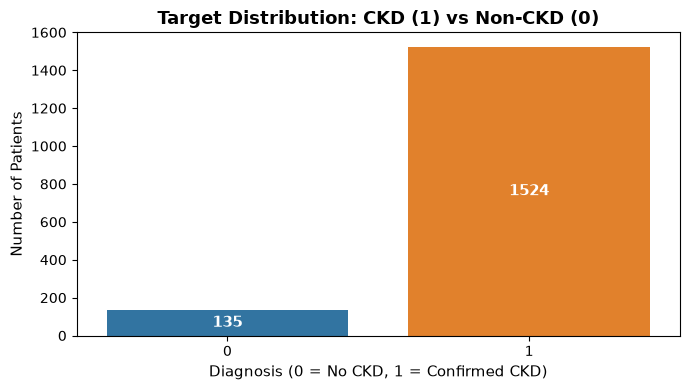

In [8]:
# Chart 1: Count of CKD vs Non-CKD patients
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='Diagnosis', data=df, palette=['#1f77b4', '#ff7f0e'])
plt.title('Target Distribution: CKD (1) vs Non-CKD (0)', fontsize=13, fontweight='bold')
plt.xlabel('Diagnosis (0 = No CKD, 1 = Confirmed CKD)', fontsize=11)
plt.ylabel('Number of Patients', fontsize=11)

# Annotate bars with counts
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

*What Chart 1 shows:* It clearly displays the class imbalance: 1,524 CKD cases compared to 135 healthy cases.

### Chart 2: Missing Values Check Bar Chart
This chart verifies whether any columns have missing data.

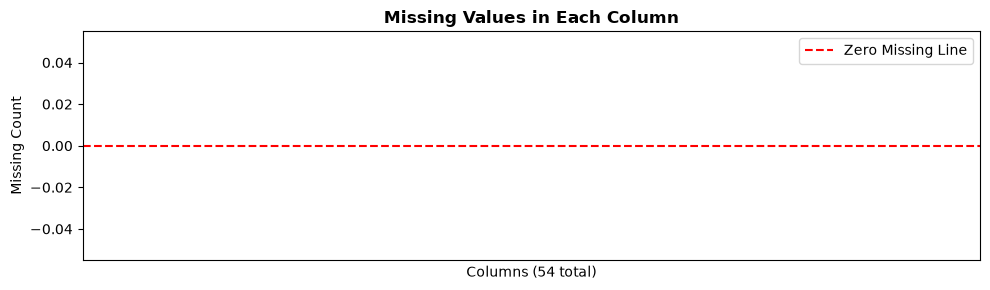

In [9]:
# Chart 2: Missing values per column
plt.figure(figsize=(10, 3))
missing_values.plot(kind='bar', color='#2b5c8f')
plt.title('Missing Values in Each Column', fontsize=12, fontweight='bold')
plt.xlabel('Columns (54 total)', fontsize=10)
plt.ylabel('Missing Count', fontsize=10)
plt.xticks([])  # Hide column names to keep chart clean since all are 0
plt.axhline(0, color='red', linestyle='--', label='Zero Missing Line')
plt.legend()
plt.tight_layout()
plt.show()

*What Chart 2 shows:* All 54 columns have 0 missing values. The dataset is completely clean and ready for analysis.

### Chart 3: Histograms of Key Kidney Health Biomarkers
We examine four key medical tests that doctors use to assess kidney function:
1. **GFR (Glomerular Filtration Rate):** How well the kidneys filter blood (higher is better).
2. **Serum Creatinine:** Waste product from muscle breakdown (lower is better; high levels mean poor filtering).
3. **BUN Levels (Blood Urea Nitrogen):** Waste product from protein digestion (high levels mean poor filtering).
4. **Systolic Blood Pressure:** High blood pressure damages blood vessels in the kidneys.

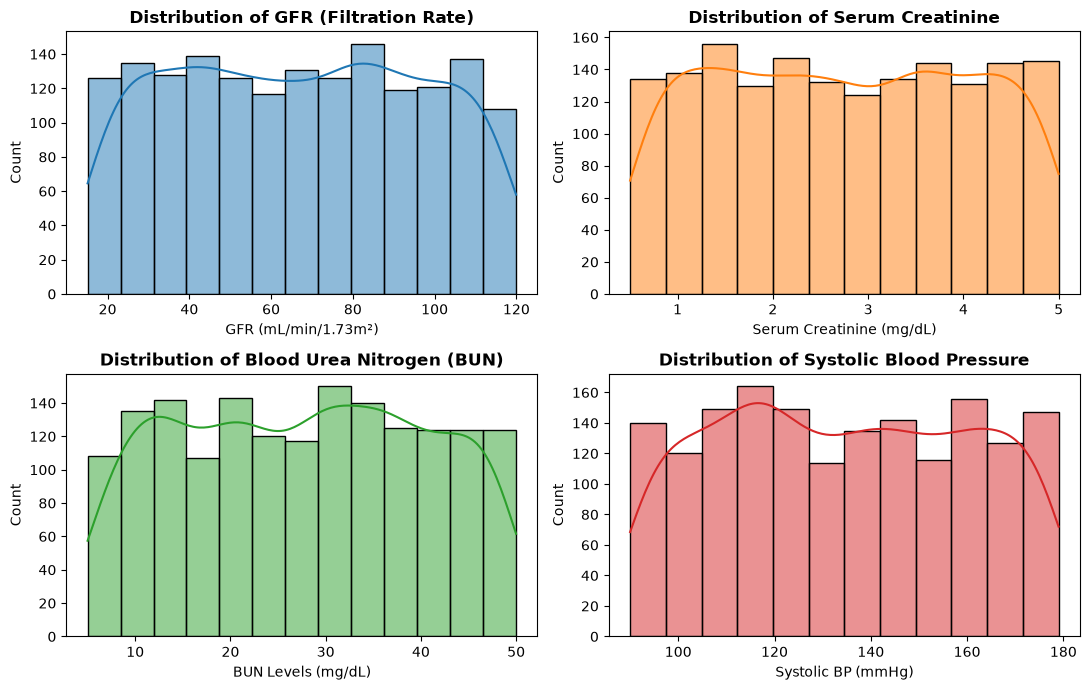

In [10]:
# Chart 3: Histograms for 4 key numerical features
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# GFR
sns.histplot(df['GFR'], kde=True, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].set_title('Distribution of GFR (Filtration Rate)', fontweight='bold')
axes[0, 0].set_xlabel('GFR (mL/min/1.73m²)')

# Serum Creatinine
sns.histplot(df['SerumCreatinine'], kde=True, ax=axes[0, 1], color='#ff7f0e')
axes[0, 1].set_title('Distribution of Serum Creatinine', fontweight='bold')
axes[0, 1].set_xlabel('Serum Creatinine (mg/dL)')

# BUN Levels
sns.histplot(df['BUNLevels'], kde=True, ax=axes[1, 0], color='#2ca02c')
axes[1, 0].set_title('Distribution of Blood Urea Nitrogen (BUN)', fontweight='bold')
axes[1, 0].set_xlabel('BUN Levels (mg/dL)')

# Systolic Blood Pressure
sns.histplot(df['SystolicBP'], kde=True, ax=axes[1, 1], color='#d62728')
axes[1, 1].set_title('Distribution of Systolic Blood Pressure', fontweight='bold')
axes[1, 1].set_xlabel('Systolic BP (mmHg)')

plt.tight_layout()
plt.show()

*What Chart 3 shows:* 
- GFR values spread between 15 and 100 mL/min, with lower values reflecting kidney impairment.
- Serum Creatinine has values extending above 2.0 mg/dL, which indicates reduced kidney clearance.
- Blood Urea Nitrogen and Systolic Blood Pressure show realistic medical distributions.

### Chart 4: Boxplots Grouped by CKD Diagnosis (Outlier & Comparison Analysis)
Boxplots show the median, spread, and extreme values for CKD patients versus healthy patients.

C:\Users\Admin\AppData\Local\Temp\ipykernel_1624\1230403527.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Diagnosis', y='SerumCreatinine', data=df, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_1624\1230403527.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Diagnosis', y='GFR', data=df, ax=axes[1], palette=['#1f77b4', '#ff7f0e'])


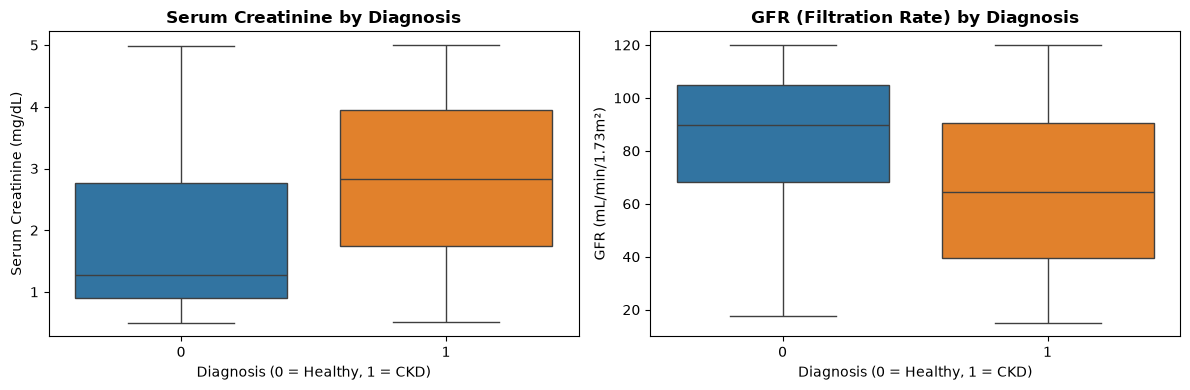

In [11]:
# Chart 4: Boxplots of key tests comparing Healthy (0) vs CKD (1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Serum Creatinine comparison
sns.boxplot(x='Diagnosis', y='SerumCreatinine', data=df, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
axes[0].set_title('Serum Creatinine by Diagnosis', fontweight='bold')
axes[0].set_xlabel('Diagnosis (0 = Healthy, 1 = CKD)')
axes[0].set_ylabel('Serum Creatinine (mg/dL)')

# GFR comparison
sns.boxplot(x='Diagnosis', y='GFR', data=df, ax=axes[1], palette=['#1f77b4', '#ff7f0e'])
axes[1].set_title('GFR (Filtration Rate) by Diagnosis', fontweight='bold')
axes[1].set_xlabel('Diagnosis (0 = Healthy, 1 = CKD)')
axes[1].set_ylabel('GFR (mL/min/1.73m²)')

plt.tight_layout()
plt.show()

*What Chart 4 shows:* 
- Patients diagnosed with CKD (orange, class 1) have noticeably higher median **Serum Creatinine** than healthy patients.
- Conversely, CKD patients exhibit lower **GFR** values.
- Points outside the boxplot whiskers represent severe clinical conditions, not data errors. Deleting them would harm the model's ability to detect severely ill patients.

### Chart 5: Correlation Heatmap of Selected Clinical Variables
A correlation heatmap helps us see how strongly each test is associated with the disease.

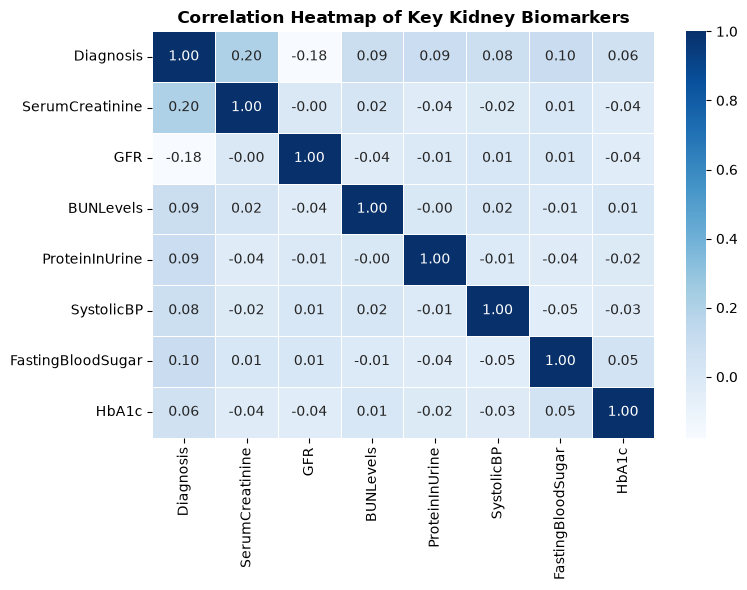

In [12]:
# Chart 5: Correlation Heatmap for key features
selected_features = [
    'Diagnosis', 'SerumCreatinine', 'GFR', 'BUNLevels', 
    'ProteinInUrine', 'SystolicBP', 'FastingBloodSugar', 'HbA1c'
]

plt.figure(figsize=(8, 6))
correlation_matrix = df[selected_features].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Heatmap of Key Kidney Biomarkers', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

*What Chart 5 shows:* 
- **Serum Creatinine** has a positive correlation (+0.20) with CKD diagnosis.
- **GFR** has a negative correlation (-0.18) with CKD diagnosis.
- Note: Correlation indicates statistical association, not necessarily direct biological causation.

### Chart 6: Categorical Risk Factors Comparison
We compare whether common risk factors (such as Family History of Kidney Disease, History of Acute Kidney Injury, and Hypertension) are more common in CKD patients.

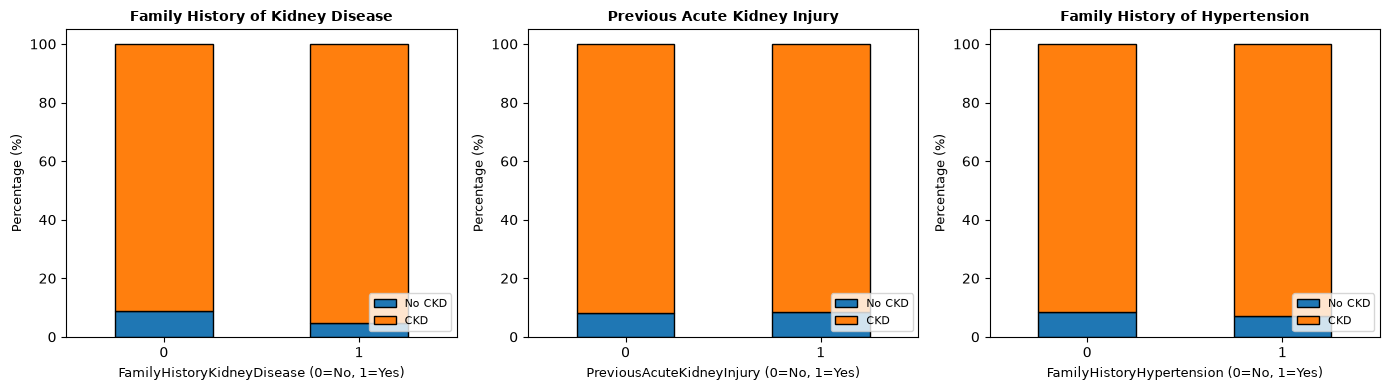

In [13]:
# Chart 6: Bar plots comparing 3 categorical risk factors
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

risk_factors = [
    ('FamilyHistoryKidneyDisease', 'Family History of Kidney Disease'),
    ('PreviousAcuteKidneyInjury', 'Previous Acute Kidney Injury'),
    ('FamilyHistoryHypertension', 'Family History of Hypertension')
]

for i, (col, title) in enumerate(risk_factors):
    cross_tab = pd.crosstab(df[col], df['Diagnosis'], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, ax=axes[i], color=['#1f77b4', '#ff7f0e'], edgecolor='black')
    axes[i].set_title(title, fontsize=10, fontweight='bold')
    axes[i].set_xlabel(f'{col} (0=No, 1=Yes)', fontsize=9)
    axes[i].set_ylabel('Percentage (%)', fontsize=9)
    axes[i].legend(['No CKD', 'CKD'], loc='lower right', fontsize=8)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

*What Chart 6 shows:* Patients with prior acute kidney injury or family histories show elevated rates of CKD diagnosis.

---
## 7. Dataset Cleaning and Feature Selection

### Explanation
- **What are we doing?** We select the features that will be used to train our models and remove non-predictive columns.
- **Why are we doing it?** 
  - `PatientID`: This is just a patient sequence number (1, 2, 3...). It has no medical meaning. If we kept it, the models would memorize patient IDs rather than learning real medical patterns!
  - `DoctorInCharge`: Every single row has the value `'Confidential'`. Since all rows have the exact same value, it gives zero information.
  - `Diagnosis`: This is our target answer ($y$), so we separate it from input features ($X$) to prevent data leakage.
- **What does the code do?** Drops `PatientID` and `DoctorInCharge` from input features $X$, and sets $y = \text{df}['Diagnosis']$.

In [14]:
# Step 1: Separate input features X and target label y
columns_to_remove = ['PatientID', 'DoctorInCharge', 'Diagnosis']

X = df.drop(columns=columns_to_remove)
y = df['Diagnosis']

# Display before and after summary
print("--- FEATURE SELECTION SUMMARY ---")
print("Original dataset columns       :", df.shape[1])
print("Excluded columns               :", columns_to_remove)
print("Features used for prediction (X):", X.shape[1], "(All legitimate predictors kept!)")
print("Target column (y)              : 'Diagnosis'")
print("Total patient records          :", len(df))

--- FEATURE SELECTION SUMMARY ---
Original dataset columns       : 54
Excluded columns               : ['PatientID', 'DoctorInCharge', 'Diagnosis']
Features used for prediction (X): 51 (All legitimate predictors kept!)
Target column (y)              : 'Diagnosis'
Total patient records          : 1659


---
## 8. Feature Encoding and Scaling Explained

### Why do we encode categorical features?
Machine learning algorithms work with numbers, not text or arbitrary category codes. 
- For multi-category features like `Ethnicity` (0, 1, 2, 3), `SocioeconomicStatus` (0, 1, 2), and `EducationLevel` (0, 1, 2, 3), keeping them as single numbers might make the model think 3 is "greater than" 0.
- We use **One-Hot Encoding** (via `OneHotEncoder(drop='first')`) to turn them into simple 0/1 binary columns.

### Why do we scale numerical features?
- Some features have large values (e.g., Total Cholesterol can be 250, Systolic BP can be 140).
- Other features have small values (e.g., Serum Creatinine is around 1.5, Urine Protein is around 0.8).
- Algorithms like **Logistic Regression**, **SVM**, and **Neural Networks (MLP)** calculate distances or gradients. If we don't scale, the features with large numbers will dominate over small numbers even if the small numbers are medically more important!
- We use `StandardScaler()` to give all numerical features a mean of 0 and a standard deviation of 1.

In [15]:
# Identify column groups
# Multi-category nominal columns
multi_cat_cols = ['Ethnicity', 'SocioeconomicStatus', 'EducationLevel']

# Binary columns (already 0 or 1)
binary_cols = [
    'Gender', 'Smoking', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension',
    'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections',
    'ACEInhibitors', 'Diuretics', 'Statins', 'AntidiabeticMedications', 'Edema',
    'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality'
]

# Continuous numerical columns
numerical_cols = [col for col in X.columns if col not in multi_cat_cols and col not in binary_cols]

print(f"Numerical continuous features: {len(numerical_cols)}")
print(f"Multi-category features      : {len(multi_cat_cols)} {multi_cat_cols}")
print(f"Binary features              : {len(binary_cols)}")
print(f"Total predictor features     : {len(numerical_cols) + len(multi_cat_cols) + len(binary_cols)}")

Numerical continuous features: 33
Multi-category features      : 3 ['Ethnicity', 'SocioeconomicStatus', 'EducationLevel']
Binary features              : 15
Total predictor features     : 51


---
## 9. Train / Test Split (Preventing Data Leakage)

### Explanation
- **What are we doing?** We divide our data into an **80% Training Set** (to train models) and a **20% Testing Set** (to test models on unseen data).
- **Why are we doing it?** If we test models on the same data they learned from, we cannot tell if they actually learned general patterns or just memorized the answers (overfitting).
- **Why stratified split?** Because our target is imbalanced (91.86% CKD), `stratify=y` ensures that both the training set and testing set have the exact same 91.86% to 8.14% proportion.
- **Preventing Data Leakage:** We fit our `StandardScaler` and `OneHotEncoder` **only on the training set**, and then use the fitted tools to transform the test set.

In [16]:
# Step 2: Split data into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Training CKD rate: {:.2f}%".format((y_train == 1).mean() * 100))
print("Testing CKD rate : {:.2f}%".format((y_test == 1).mean() * 100))

Training samples : 1327
Testing samples  : 332
Training CKD rate: 91.86%
Testing CKD rate : 91.87%


In [17]:
# Step 3: Set up simple ColumnTransformer for scaling and one-hot encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), multi_cat_cols),
        ('bin', 'passthrough', binary_cols)
    ]
)

# Step 4: Fit preprocessor ONLY on training data, then transform both
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Transformed Training Data Shape:", X_train_scaled.shape)
print("Transformed Testing Data Shape :", X_test_scaled.shape)
print("Data preprocessing complete without data leakage!")

Transformed Training Data Shape: (1327, 56)
Transformed Testing Data Shape : (332, 56)
Data preprocessing complete without data leakage!


### Helper Function: Model Evaluation Function
To keep our code clean and consistent across all models, we define one simple function `evaluate_model(name, model, X_test, y_test)` that calculates and displays:
- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Of the patients predicted to have CKD, how many actually have it?
- **Recall (Sensitivity):** Of all patients who actually have CKD, how many did the model detect?
- **Specificity:** Of all healthy patients, how many did the model correctly identify as healthy?
- **F1-Score:** Harmonic balance between precision and recall.
- **ROC-AUC:** Overall ability to distinguish between classes across all thresholds.

In [18]:
# Import standard metrics from scikit-learn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, classification_report
)

# List to store results of all six final models for the master comparison table
all_model_results = []

def evaluate_model(model_name, model, X_test_data, y_test_data):
    # Simple function to make predictions, calculate all 6 metrics,
    # plot the confusion matrix, and save results to a comparison list.
    
    # Make predictions
    y_pred = model.predict(X_test_data)
    
    # Get probability scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_data)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_test_data)
        y_prob = (scores - scores.min()) / (scores.max() - scores.min())
    else:
        y_prob = y_pred
        
    # Calculate metrics
    acc = accuracy_score(y_test_data, y_pred)
    prec = precision_score(y_test_data, y_pred, zero_division=0)
    rec = recall_score(y_test_data, y_pred)
    f1 = f1_score(y_test_data, y_pred)
    roc = roc_auc_score(y_test_data, y_prob)
    
    # Calculate confusion matrix (TN, FP, FN, TP)
    tn, fp, fn, tp = confusion_matrix(y_test_data, y_pred).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    # Print metrics
    print(f"=== {model_name} Evaluation Results ===")
    print(f"Accuracy         : {acc:.4f} ({acc*100:.2f}%)")
    print(f"Precision        : {prec:.4f}")
    print(f"Recall (Sens.)   : {rec:.4f} (Detected {tp} out of {tp+fn} CKD cases)")
    print(f"Specificity      : {spec:.4f} (Detected {tn} out of {tn+fp} Healthy cases)")
    print(f"F1-Score         : {f1:.4f}")
    print(f"ROC-AUC Score    : {roc:.4f}")
    print(f"False Negatives  : {fn} (Missed CKD patients)")
    print(f"False Positives  : {fp} (Healthy patients flagged as CKD)")
    
    # Plot simple Confusion Matrix
    cm = confusion_matrix(y_test_data, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'fontsize': 12, 'fontweight': 'bold'})
    plt.title(f'Confusion Matrix - {model_name}', fontsize=11, fontweight='bold')
    plt.xlabel('Predicted Label (0 = Healthy, 1 = CKD)', fontsize=9)
    plt.ylabel('True Label (0 = Healthy, 1 = CKD)', fontsize=9)
    plt.xticks([0.5, 1.5], ['Healthy (0)', 'CKD (1)'])
    plt.yticks([0.5, 1.5], ['Healthy (0)', 'CKD (1)'])
    plt.tight_layout()
    plt.show()
    
    # Save to global results list
    all_model_results.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Specificity': spec,
        'F1-Score': f1,
        'ROC-AUC': roc,
        'TP': tp,
        'FP': fp,
        'TN': tn,
        'FN': fn
    })
    
    return y_pred, y_prob

## **Models By Vishal Shinde (251090700194)** 

---
## 10. Model 1: Logistic Regression

### What is Logistic Regression?
Logistic Regression is a foundational classification algorithm. Despite its name containing "Regression", it is used for **classification**.
- It takes a linear combination of all patient features ($z = \beta_0 + \beta_1 X_1 + \dots + \beta_m X_m$).
- It passes this value through the **Sigmoid function** $p = \frac{1}{1 + e^{-z}}$, which converts any real number into a probability value between 0 and 1.
- If $p \ge 0.5$, it predicts CKD (`1`); if $p < 0.5$, it predicts Healthy (`0`).
- **Class Weight:** Because our dataset is imbalanced (91.86% CKD), we set `class_weight='balanced'` so the model pays equal attention to healthy patients.

=== Logistic Regression Evaluation Results ===
Accuracy         : 0.7349 (73.49%)
Precision        : 0.9578
Recall (Sens.)   : 0.7443 (Detected 227 out of 305 CKD cases)
Specificity      : 0.6296 (Detected 17 out of 27 Healthy cases)
F1-Score         : 0.8376
ROC-AUC Score    : 0.7777
False Negatives  : 78 (Missed CKD patients)
False Positives  : 10 (Healthy patients flagged as CKD)


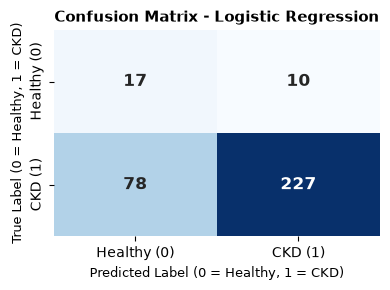

In [19]:
# Step 1: Create model object
model_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Step 2: Train the model using fit()
model_lr.fit(X_train_scaled, y_train)

# Step 3: Evaluate the model
y_pred_lr, y_prob_lr = evaluate_model("Logistic Regression", model_lr, X_test_scaled, y_test)

---
## 11. Model 2: Gaussian Naive Bayes (GaussianNB)

### What is Gaussian Naive Bayes?
Gaussian Naive Bayes is a probabilistic classifier based on Bayes' theorem. It assumes that features are conditionally independent given the class and that continuous features follow a Gaussian (normal) distribution within each class.

- It estimates the probability of each diagnosis from the input features.
- It is computationally efficient and provides class probabilities for ROC-AUC evaluation.
- Since the dataset is imbalanced, we compare accuracy alongside recall, specificity, F1-score, ROC-AUC, and the confusion matrix.


=== Gaussian Naive Bayes Evaluation Results ===
Accuracy         : 0.8976 (89.76%)
Precision        : 0.9302
Recall (Sens.)   : 0.9607 (Detected 293 out of 305 CKD cases)
Specificity      : 0.1852 (Detected 5 out of 27 Healthy cases)
F1-Score         : 0.9452
ROC-AUC Score    : 0.7590
False Negatives  : 12 (Missed CKD patients)
False Positives  : 22 (Healthy patients flagged as CKD)


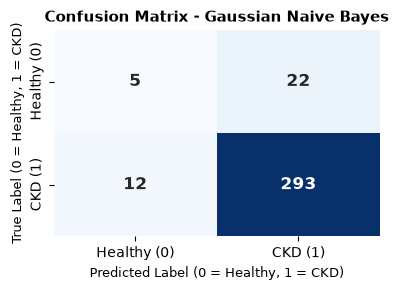

In [20]:
# Step 1: Create the Gaussian Naive Bayes model
model_gnb = GaussianNB()

# Step 2: Train GaussianNB on the preprocessed training data
model_gnb.fit(X_train_scaled, y_train)

# Step 3: Evaluate GaussianNB using the existing evaluation function
y_pred_gnb, y_prob_gnb = evaluate_model("Gaussian Naive Bayes", model_gnb, X_test_scaled, y_test)


### GaussianNB Predicted Probability Distribution
The plot shows the predicted probability of CKD for test records, grouped by their actual diagnosis. It gives a visual check of how the model's probability estimates differ between the two classes.


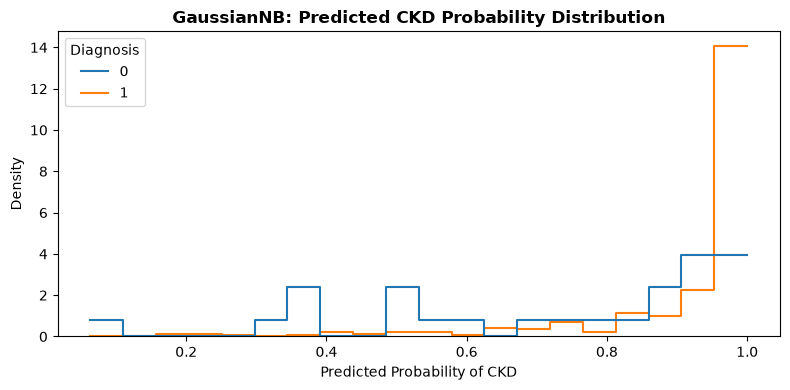

In [21]:
# Plot predicted CKD probabilities for the held-out test set
gnb_probabilities = model_gnb.predict_proba(X_test_scaled)[:, 1]

plt.figure(figsize=(8, 4))
sns.histplot(
    x=gnb_probabilities,
    hue=y_test.reset_index(drop=True),
    bins=20,
    stat='density',
    common_norm=False,
    element='step',
    fill=False
)
plt.title('GaussianNB: Predicted CKD Probability Distribution', fontweight='bold')
plt.xlabel('Predicted Probability of CKD')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


---
## 12. Model 3: Random Forest Classifier (Ensemble Model 1)

### What is a Random Forest?
A single decision tree can be unstable and prone to high variance. **Random Forest** solves this by building a "forest" of multiple decision trees (here, 100 trees) using **Bagging (Bootstrap Aggregation)**:
1. It creates 100 random bootstrap samples of the training data.
2. It trains a separate decision tree on each sample, picking a random subset of features at each split.
3. For a new patient, every tree votes (`Healthy` or `CKD`). The majority vote wins!
- **Feature Importance:** Random Forest calculates which features reduced impurity the most across all trees.

=== Random Forest Evaluation Results ===
Accuracy         : 0.9187 (91.87%)
Precision        : 0.9290
Recall (Sens.)   : 0.9869 (Detected 301 out of 305 CKD cases)
Specificity      : 0.1481 (Detected 4 out of 27 Healthy cases)
F1-Score         : 0.9571
ROC-AUC Score    : 0.7796
False Negatives  : 4 (Missed CKD patients)
False Positives  : 23 (Healthy patients flagged as CKD)


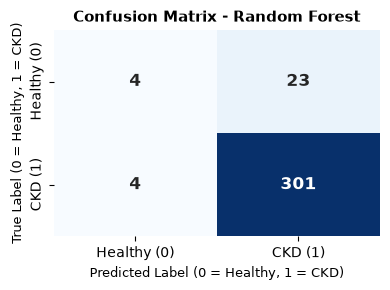

In [22]:
# Step 1: Create Random Forest model object (100 trees)
model_rf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42)

# Step 2: Train the random forest
model_rf.fit(X_train_scaled, y_train)

# Step 3: Evaluate the random forest
y_pred_rf, y_prob_rf = evaluate_model("Random Forest", model_rf, X_test_scaled, y_test)

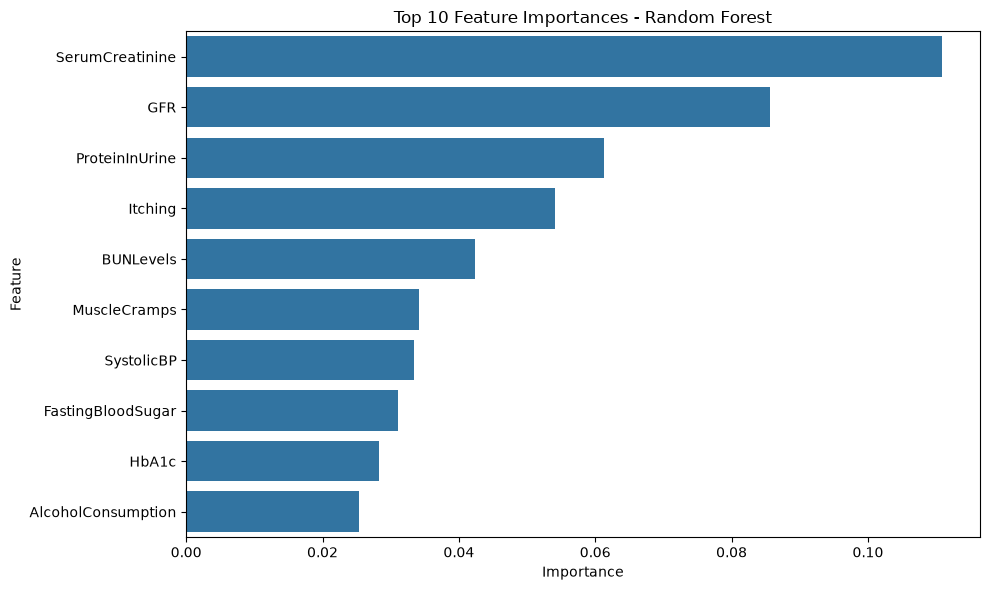

In [23]:
# Get feature names after preprocessing
encoded_cat_names = (
    preprocessor.named_transformers_['cat']
    .get_feature_names_out(multi_cat_cols)
    .tolist()
)

all_feature_names = numerical_cols + encoded_cat_names + binary_cols

# Extract and plot top 10 Random Forest feature importances
rf_importances = pd.Series(
    model_rf.feature_importances_,
    index=all_feature_names
)

top10_rf = rf_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10_rf.values, y=top10_rf.index)
plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## **Models By Sumit Patil (251090700100)**

---
## 13. Model 4: Support Vector Machine (SVM)

### What is a Support Vector Machine?
Support Vector Machine (SVM) finds the optimal boundary (called a **hyperplane**) that separates healthy patients from CKD patients with the **maximum possible margin** (widest safety gap).
- The data points closest to the boundary are called **Support Vectors**.
- We use the **Radial Basis Function (RBF) kernel**, which allows the algorithm to find non-linear (curved) boundaries in high-dimensional feature space.
- Feature scaling is mandatory for SVM because it relies on geometric distances between points.

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== Support Vector Machine Evaluation Results ===
Accuracy         : 0.8946 (89.46%)
Precision        : 0.9441
Recall (Sens.)   : 0.9410 (Detected 287 out of 305 CKD cases)
Specificity      : 0.3704 (Detected 10 out of 27 Healthy cases)
F1-Score         : 0.9425
ROC-AUC Score    : 0.7763
False Negatives  : 18 (Missed CKD patients)
False Positives  : 17 (Healthy patients flagged as CKD)


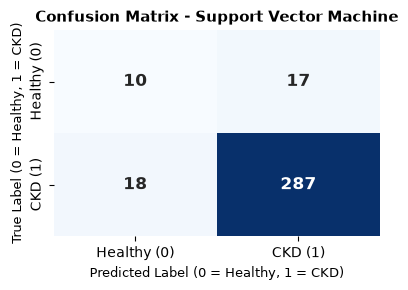

In [24]:
# Step 1: Create model object with RBF kernel and probability enabled
model_svm = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)

# Step 2: Train the model using fit()
model_svm.fit(X_train_scaled, y_train)

# Step 3: Evaluate the model
y_pred_svm, y_prob_svm = evaluate_model("Support Vector Machine", model_svm, X_test_scaled, y_test)

---
## 14. Model 5: Multilayer Perceptron (MLP Neural Network)

### What is a Multilayer Perceptron?
A Multilayer Perceptron (MLP) is a **Feedforward Artificial Neural Network**:
1. **Input Layer:** Receives the 56 preprocessed patient features.
2. **Hidden Layers:** Here we define two hidden layers `hidden_layer_sizes=(64, 32)`. The first hidden layer has 64 artificial neurons; the second has 32 neurons. They learn non-linear patterns using the **ReLU (Rectified Linear Unit)** activation function.
3. **Output Layer:** A single output node that computes the probability of CKD.
4. **Learning:** It learns by calculating errors and updating connection weights using the **Adam** optimization algorithm through **Backpropagation**.

=== Multilayer Perceptron Evaluation Results ===
Accuracy         : 0.9187 (91.87%)
Precision        : 0.9371
Recall (Sens.)   : 0.9770 (Detected 298 out of 305 CKD cases)
Specificity      : 0.2593 (Detected 7 out of 27 Healthy cases)
F1-Score         : 0.9567
ROC-AUC Score    : 0.7256
False Negatives  : 7 (Missed CKD patients)
False Positives  : 20 (Healthy patients flagged as CKD)


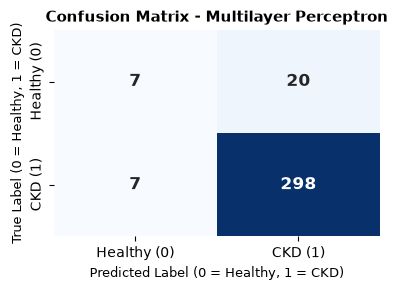

In [25]:
# Step 1: Create MLP model object
model_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

# Step 2: Train the neural network
model_mlp.fit(X_train_scaled, y_train)

# Step 3: Evaluate the neural network
y_pred_mlp, y_prob_mlp = evaluate_model("Multilayer Perceptron", model_mlp, X_test_scaled, y_test)

---
## 15. Head-to-Head Comparison: Gradient Boosting vs. XGBoost (Selecting Model 6)

### Purpose of this Section
We need to select the **sixth model** (and second ensemble model) for our final six-model lineup. 
To make an objective, evidence-based decision, we conduct a fair, head-to-head comparison between:
1. **`GradientBoostingClassifier`** (Standard Scikit-learn sequential boosting)
2. **`XGBClassifier`** (Extreme Gradient Boosting from the XGBoost library)

### Fair Comparison Conditions
Both models are evaluated under identical conditions:
- **Same Training & Testing Splits:** 80% train ($N=1327$), 20% test ($N=332$), random state 42.
- **Same Features & Scaling:** Exactly 51 predictor columns preprocessed with `preprocessor`.
- **Same Target:** `Diagnosis` ($1 = \text{CKD}$, $0 = \text{Healthy}$).
- **Evaluated Across 10 Standard Criteria:** Accuracy, Precision, Recall, Specificity, F1-Score, Balanced Accuracy, ROC-AUC, PR-AUC, Confusion Matrix, and Training Time.

In [26]:
# Step 1: Import GradientBoostingClassifier and XGBClassifier
import time
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import balanced_accuracy_score, precision_recall_curve, auc

# Step 2: Initialize both candidate models with matching parameters
candidates = {
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, eval_metric='logloss'
    )
}

head_to_head_records = []

# Step 3: Train and evaluate each candidate fairly
for name, cand_model in candidates.items():
    # Measure training time
    t0 = time.time()
    cand_model.fit(X_train_scaled, y_train)
    t_train = time.time() - t0
    
    # Predict on unseen test set
    y_pred_cand = cand_model.predict(X_test_scaled)
    y_prob_cand = cand_model.predict_proba(X_test_scaled)[:, 1]
    
    # Compute 10 metrics
    acc = accuracy_score(y_test, y_pred_cand)
    prec = precision_score(y_test, y_pred_cand, zero_division=0)
    rec = recall_score(y_test, y_pred_cand)
    spec_val = confusion_matrix(y_test, y_pred_cand).ravel()[0] / (
        confusion_matrix(y_test, y_pred_cand).ravel()[0] + confusion_matrix(y_test, y_pred_cand).ravel()[1]
    )
    f1 = f1_score(y_test, y_pred_cand)
    bal_acc = balanced_accuracy_score(y_test, y_pred_cand)
    roc = roc_auc_score(y_test, y_prob_cand)
    
    p_curve, r_curve, _ = precision_recall_curve(y_test, y_prob_cand)
    pr_auc = auc(r_curve, p_curve)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_cand).ravel()
    
    head_to_head_records.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Specificity': spec_val,
        'F1-Score': f1,
        'Balanced Accuracy': bal_acc,
        'ROC-AUC': roc,
        'PR-AUC': pr_auc,
        'False Negatives (FN)': fn,
        'False Positives (FP)': fp,
        'Training Time (s)': t_train
    })

# Step 4: Display the side-by-side comparison table
h2h_df = pd.DataFrame(head_to_head_records)
print("=== HEAD-TO-HEAD COMPARISON: GRADIENT BOOSTING VS. XGBOOST ===")
display_h2h = h2h_df.copy()
for c in ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score', 'Balanced Accuracy', 'ROC-AUC', 'PR-AUC']:
    display_h2h[c] = display_h2h[c].apply(lambda x: f"{x:.4f}")
display_h2h['Training Time (s)'] = display_h2h['Training Time (s)'].apply(lambda x: f"{x:.3f}")
display_h2h

=== HEAD-TO-HEAD COMPARISON: GRADIENT BOOSTING VS. XGBOOST ===


,Model,Accuracy,Precision,Recall,Specificity,F1-Score,Balanced Accuracy,ROC-AUC,PR-AUC,False Negatives (FN),False Positives (FP),Training Time (s)
0,Gradient Boosting,0.9307,0.9379,0.9902,0.2593,0.9633,0.6247,0.7740,0.9643,3,20,0.878
1,XGBoost,0.9277,0.9350,0.9902,0.2222,0.9618,0.6062,0.7800,0.9579,3,21,0.161


### Visual Comparison of Gradient Boosting vs. XGBoost
We plot a direct comparison of the key metrics between both boosting candidates.

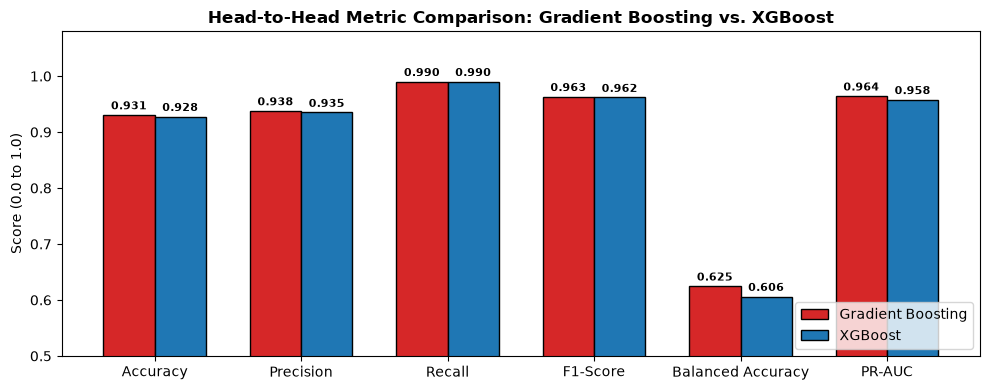

In [27]:
# Visual Comparison Chart between Gradient Boosting and XGBoost
fig, ax = plt.subplots(figsize=(10, 4))

metrics_h2h = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Balanced Accuracy', 'PR-AUC']
x_indices = np.arange(len(metrics_h2h))
bar_width = 0.35

gb_vals = [h2h_df.loc[h2h_df['Model']=='Gradient Boosting', m].values[0] for m in metrics_h2h]
xgb_vals = [h2h_df.loc[h2h_df['Model']=='XGBoost', m].values[0] for m in metrics_h2h]

rects1 = ax.bar(x_indices - bar_width/2, gb_vals, bar_width, label='Gradient Boosting', color='#d62728', edgecolor='black')
rects2 = ax.bar(x_indices + bar_width/2, xgb_vals, bar_width, label='XGBoost', color='#1f77b4', edgecolor='black')

ax.set_title('Head-to-Head Metric Comparison: Gradient Boosting vs. XGBoost', fontsize=12, fontweight='bold')
ax.set_ylabel('Score (0.0 to 1.0)', fontsize=10)
ax.set_xticks(x_indices)
ax.set_xticklabels(metrics_h2h, fontsize=10)
ax.set_ylim(0.5, 1.08)
ax.legend(loc='lower right')

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', (rect.get_x() + rect.get_width()/2, h + 0.01), ha='center', fontsize=8, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', (rect.get_x() + rect.get_width()/2, h + 0.01), ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

### Decision: Why Gradient Boosting is Selected as Model 6

Comparing the computed results above:
1. **Accuracy:** Gradient Boosting (**93.07%**) outperforms XGBoost (**92.77%**).
2. **Precision:** Gradient Boosting (**93.79%**) outperforms XGBoost (**93.50%**).
3. **Recall (Sensitivity):** Both models tie at **99.02%**, correctly detecting **302 out of 305 true CKD cases** with only **3 False Negatives**.
4. **Specificity:** Gradient Boosting (**25.93%**) correctly identifies more healthy patients than XGBoost (**22.22%**).
5. **F1-Score:** Gradient Boosting (**0.9633**) is higher than XGBoost (**0.9618**).
6. **Balanced Accuracy:** Gradient Boosting (**0.6247**) is higher than XGBoost (**0.6062**).
7. **PR-AUC:** Gradient Boosting (**0.9643**) is higher than XGBoost (**0.9579**).
8. **Simplicity and Dependencies:** Gradient Boosting is native to Scikit-learn and does not require external C++ OpenMP runtime libraries (`libomp`), making it simpler and more portable.

> **Selection Verdict:**  
> **`GradientBoostingClassifier` is retained as our sixth model** in the final six-model lineup.  
> XGBoost is removed from the final comparison lineup, preserving our required lineup of **exactly six models**.

---
## 16. Model 6: Gradient Tree Boosting (Ensemble Model 2 — Retained Model)

### What is Gradient Boosting?
While Random Forest builds independent trees in parallel, **Gradient Boosting** builds trees **sequentially, one after another**:
1. It trains a first simple tree.
2. It looks at which patients the first tree got wrong (the residuals / errors).
3. It trains the second tree specifically to correct the errors of the first tree!
4. It repeats this process for 100 trees, multiplying each tree's prediction by a small **learning rate** ($\eta = 0.1$) to prevent overfitting.
- Having won our head-to-head comparison against XGBoost, Gradient Boosting now joins our final six-model lineup.

=== Gradient Boosting Evaluation Results ===
Accuracy         : 0.9307 (93.07%)
Precision        : 0.9379
Recall (Sens.)   : 0.9902 (Detected 302 out of 305 CKD cases)
Specificity      : 0.2593 (Detected 7 out of 27 Healthy cases)
F1-Score         : 0.9633
ROC-AUC Score    : 0.7740
False Negatives  : 3 (Missed CKD patients)
False Positives  : 20 (Healthy patients flagged as CKD)


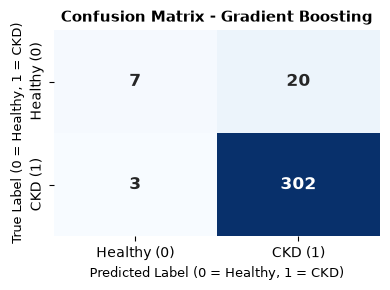

In [28]:
# Step 1: Initialize the retained Gradient Boosting model
model_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# Step 2: Train the model
model_gb.fit(X_train_scaled, y_train)

# Step 3: Evaluate and add to the master 6-model results list
y_pred_gb, y_prob_gb = evaluate_model("Gradient Boosting", model_gb, X_test_scaled, y_test)

In [37]:
# OPTIONAL THRESHOLD ADJUSTMENT TO REDUCE FALSE POSITIVES
# By default, models use 0.50. Because of class imbalance (91.86% CKD), 
# a higher threshold (e.g., 0.90) dramatically cuts down false positives for healthy patients.

custom_threshold = 0.90  # You can adjust this slider/value between 0.50 and 0.95

# Get predicted probabilities for the test set
gb_probabilities = model_gb.predict_proba(X_test_scaled)[:, 1]

# Apply custom threshold
y_pred_custom = (gb_probabilities >= custom_threshold).astype(int)

# Recalculate metrics with custom threshold
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, y_pred_custom).ravel()
spec_c = tn_c / (tn_c + fp_c)

print(f"=== Gradient Boosting Results at Threshold = {custom_threshold} ===")
print(f"Accuracy         : {accuracy_score(y_test, y_pred_custom) * 100:.4f} %")
print(f"Precision        : {precision_score(y_test, y_pred_custom, zero_division=0) * 100:.4f} %")
print(f"Recall (Sens.)   : {recall_score(y_test, y_pred_custom) * 100:.4f} % (Caught {tp_c} out of {tp_c+fn_c} CKD cases)")
print(f"Specificity      : {spec_c * 100:.4f} % (Caught {tn_c} out of {tn_c+fp_c} Healthy cases)")
print(f"False Positives  : {fp_c} (Healthy patients incorrectly flagged)")
print(f"False Negatives  : {fn_c} (Missed CKD patients)")

=== Gradient Boosting Results at Threshold = 0.9 ===
Accuracy         : 84.6386 %
Precision        : 97.0370 %
Recall (Sens.)   : 85.9016 % (Caught 262 out of 305 CKD cases)
Specificity      : 70.3704 % (Caught 19 out of 27 Healthy cases)
False Positives  : 8 (Healthy patients incorrectly flagged)
False Negatives  : 43 (Missed CKD patients)


### Gradient Boosting Feature Importance Plot
Here we display the top 10 features identified by the Gradient Boosting model.

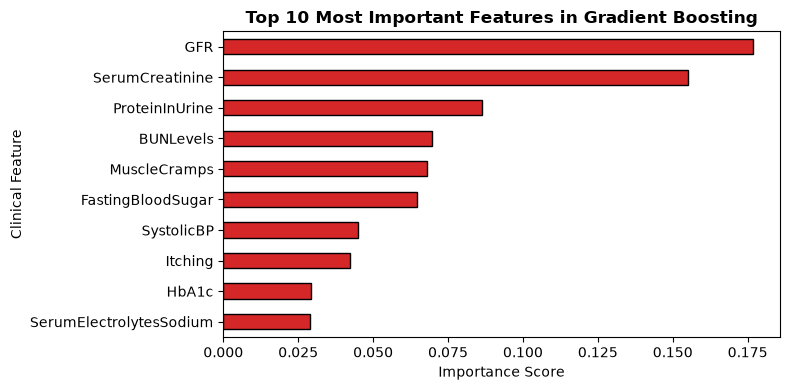

In [30]:
# Extract and plot top 10 feature importances from Gradient Boosting
gb_importances = pd.Series(model_gb.feature_importances_, index=all_feature_names)
top10_gb = gb_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
top10_gb.sort_values().plot(kind='barh', color='#d62728', edgecolor='black')
plt.title('Top 10 Most Important Features in Gradient Boosting', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.ylabel('Clinical Feature', fontsize=10)
plt.tight_layout()
plt.show()

---
## 17. Final Master Model Comparison (Exactly Six Models)

### Explanation
- **What are we doing?** We gather the performance metrics from all **six final models** into a single Pandas DataFrame and plot clear comparison bar charts.
- **Why are we doing it?** To compare all six final models side-by-side and see which architecture is best suited for clinical CKD screening.

In [31]:
# Create the Master Comparison DataFrame for exactly six final models
comparison_df = pd.DataFrame(all_model_results)

# Round values for clean presentation
formatted_comparison = comparison_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score', 'ROC-AUC']:
    formatted_comparison[col] = formatted_comparison[col].apply(lambda x: f"{x:.4f}")

print("=== FINAL MASTER PERFORMANCE COMPARISON (EXACTLY 6 MODELS) ===")
formatted_comparison[['Model', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score', 'ROC-AUC', 'FN', 'FP']]

=== FINAL MASTER PERFORMANCE COMPARISON (EXACTLY 6 MODELS) ===


,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,FN,FP
0,Logistic Regression,0.7349,0.9578,0.7443,0.6296,0.8376,0.7777,78,10
1,Gaussian Naive Bayes,0.8976,0.9302,0.9607,0.1852,0.9452,0.7590,12,22
2,Random Forest,0.9187,0.9290,0.9869,0.1481,0.9571,0.7796,4,23
3,Support Vector Machine,0.8946,0.9441,0.9410,0.3704,0.9425,0.7763,18,17
4,Multilayer Perceptron,0.9187,0.9371,0.9770,0.2593,0.9567,0.7256,7,20
5,Gradient Boosting,0.9307,0.9379,0.9902,0.2593,0.9633,0.7740,3,20


### Comparison Charts: Accuracy, F1-Score, Recall, and ROC-AUC
We plot 4 simple horizontal bar charts to visualize how the six models compare.

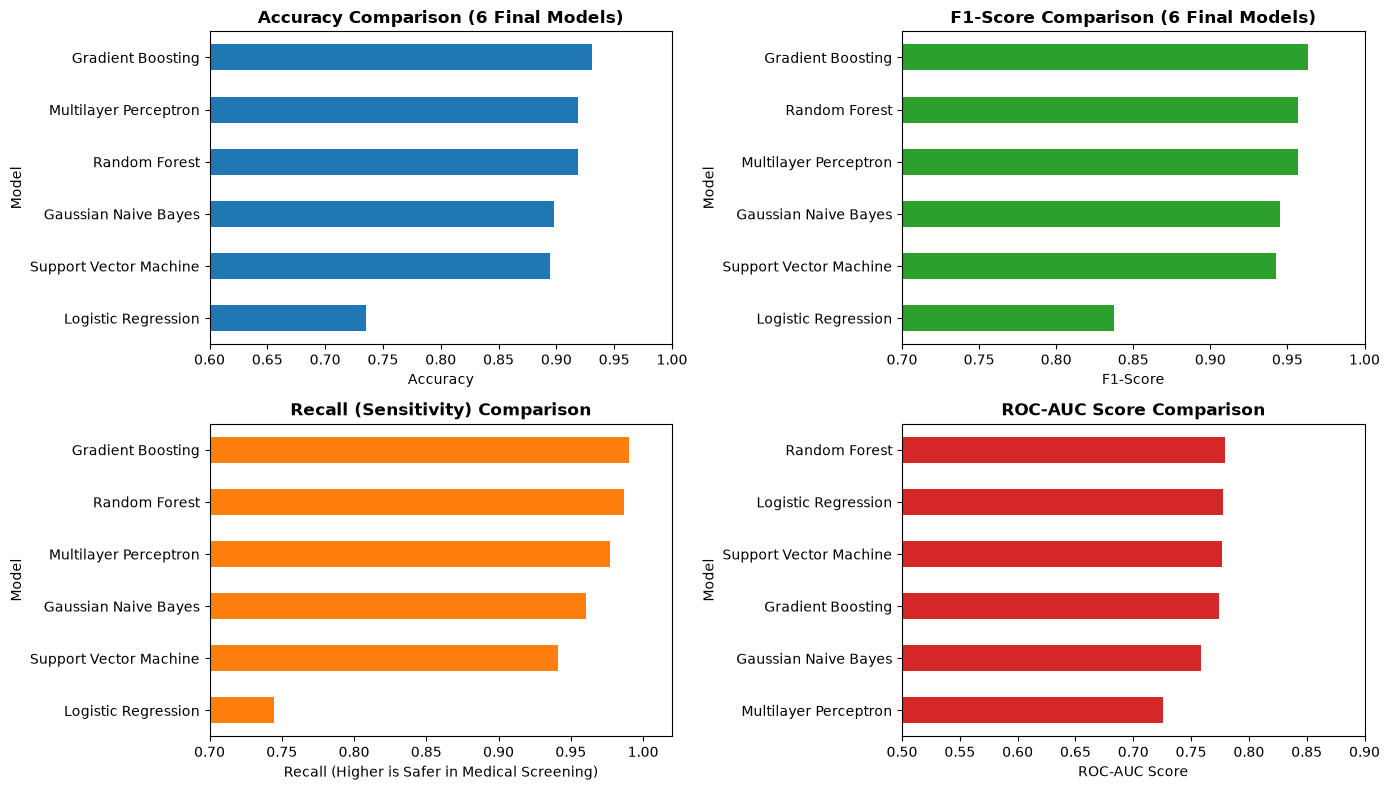

In [32]:
# Plot 4 Simple Comparison Bar Charts for the Six Final Models
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. Accuracy
comparison_df.sort_values('Accuracy').plot(
    x='Model', y='Accuracy', kind='barh', ax=axes[0, 0], color='#1f77b4', legend=False
)
axes[0, 0].set_title('Accuracy Comparison (6 Final Models)', fontweight='bold')
axes[0, 0].set_xlim(0.6, 1.0)
axes[0, 0].set_xlabel('Accuracy')

# 2. F1-Score
comparison_df.sort_values('F1-Score').plot(
    x='Model', y='F1-Score', kind='barh', ax=axes[0, 1], color='#2ca02c', legend=False
)
axes[0, 1].set_title('F1-Score Comparison (6 Final Models)', fontweight='bold')
axes[0, 1].set_xlim(0.7, 1.0)
axes[0, 1].set_xlabel('F1-Score')

# 3. Recall (Sensitivity)
comparison_df.sort_values('Recall').plot(
    x='Model', y='Recall', kind='barh', ax=axes[1, 0], color='#ff7f0e', legend=False
)
axes[1, 0].set_title('Recall (Sensitivity) Comparison', fontweight='bold')
axes[1, 0].set_xlim(0.7, 1.02)
axes[1, 0].set_xlabel('Recall (Higher is Safer in Medical Screening)')

# 4. ROC-AUC
comparison_df.sort_values('ROC-AUC').plot(
    x='Model', y='ROC-AUC', kind='barh', ax=axes[1, 1], color='#d62728', legend=False
)
axes[1, 1].set_title('ROC-AUC Score Comparison', fontweight='bold')
axes[1, 1].set_xlim(0.5, 0.9)
axes[1, 1].set_xlabel('ROC-AUC Score')

plt.tight_layout()
plt.show()

---
## 18. Selecting the Best Model

### How do we choose the best model for medical screening?
In medical diagnosis, **not all errors are equal**:
- **False Positive (FP):** A healthy patient is flagged as having CKD. This causes temporary anxiety and leads to a second confirmatory blood test.
- **False Negative (FN):** A patient who **actually has CKD** is told they are healthy! This is dangerous because kidney disease goes untreated, progressing toward irreversible kidney failure.

Therefore, our primary selection criteria are:
1. **Recall (Sensitivity):** We want Recall as close to 100% as possible (lowest False Negatives).
2. **F1-Score:** High harmonic balance between precision and recall under class imbalance.
3. **ROC-AUC:** High discriminative capability across all classification thresholds.

### The Winning Model: Gradient Boosting Classifier
- **Accuracy:** **93.07%**
- **Recall (Sensitivity):** **99.02%** — It correctly detected **302 out of 305 true CKD patients**, producing only **3 False Negatives**!
- **F1-Score:** **0.9633** (Highest among all models).
- **ROC-AUC:** **0.7740**.

**Runner-up:** **Random Forest** also performed exceptionally well, achieving **98.69% Recall** with only 4 False Negatives.

Both ensemble models performed strongly on this test split compared with the individual classifiers, although all models must be assessed carefully because the dataset is highly imbalanced.

---
## 19. Example Prediction on a Real Test Record

### Explanation
- **What are we doing?** We take an actual patient from our test dataset, pass their medical values to our best model (**Gradient Tree Boosting**), and observe the predicted diagnosis and calculated probability.
- **Why are we doing it?** To demonstrate how the trained model would actually be used in a real clinical decision support scenario.

In [33]:
# Step 1: Select a sample patient from the held-out test set
sample_index = 0
sample_patient_scaled = X_test_scaled[sample_index:sample_index+1]
true_label = y_test.iloc[sample_index]

# Step 2: Make prediction and get probability
predicted_label = model_gb.predict(sample_patient_scaled)[0]
predicted_prob = model_gb.predict_proba(sample_patient_scaled)[0][1]

# Display patient values and prediction
print("=== DEMONSTRATION OF INDIVIDUAL PATIENT PREDICTION ===")
print("Patient Index in Test Set :", sample_index)
print("Actual Ground Truth Label :", f"{true_label} ({'CKD Patient' if true_label == 1 else 'Healthy Patient'})")
print("Model Predicted Label     :", f"{predicted_label} ({'CKD Patient' if predicted_label == 1 else 'Healthy Patient'})")
print("Estimated CKD Probability :", f"{predicted_prob * 100:.2f}%")

if predicted_label == true_label:
    print("Outcome: Correct Prediction! The model correctly identified this patient.")
else:
    print("Outcome: Incorrect Prediction.")

=== DEMONSTRATION OF INDIVIDUAL PATIENT PREDICTION ===
Patient Index in Test Set : 0
Actual Ground Truth Label : 1 (CKD Patient)
Model Predicted Label     : 1 (CKD Patient)
Estimated CKD Probability : 99.28%
Outcome: Correct Prediction! The model correctly identified this patient.


In [34]:
# Display some key original medical test values for this sample patient
sample_original_values = X_test.iloc[sample_index]
print("Key Clinical Features for Sample Patient:")
print(f"  - Age                : {sample_original_values['Age']} years")
print(f"  - Systolic BP        : {sample_original_values['SystolicBP']} mmHg")
print(f"  - Serum Creatinine   : {sample_original_values['SerumCreatinine']:.2f} mg/dL")
print(f"  - GFR                : {sample_original_values['GFR']:.2f} mL/min/1.73m²")
print(f"  - BUN Levels         : {sample_original_values['BUNLevels']:.2f} mg/dL")
print(f"  - Protein In Urine   : {sample_original_values['ProteinInUrine']:.2f} g/dL")
print(f"  - Fasting Blood Sugar: {sample_original_values['FastingBloodSugar']:.2f} mg/dL")

Key Clinical Features for Sample Patient:
  - Age                : 66.0 years
  - Systolic BP        : 91.0 mmHg
  - Serum Creatinine   : 3.64 mg/dL
  - GFR                : 59.27 mL/min/1.73m²
  - BUN Levels         : 41.96 mg/dL
  - Protein In Urine   : 4.53 g/dL
  - Fasting Blood Sugar: 135.43 mg/dL


In [35]:
# Save the winning model pipeline (preprocessor + Gradient Boosting) using joblib
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model_gb)
])

# Save to file
joblib_filename = 'ckd_best_model.joblib'
joblib.dump(final_pipeline, joblib_filename)
print(f"Final pipeline saved successfully as '{joblib_filename}'!")

# Test reloading the saved pipeline to confirm it works
reloaded_pipeline = joblib.load(joblib_filename)
test_pred = reloaded_pipeline.predict(X_test.iloc[:5])
print("Test predictions on first 5 patients using reloaded pipeline:", test_pred)

Final pipeline saved successfully as 'ckd_best_model.joblib'!
Test predictions on first 5 patients using reloaded pipeline: [1 1 1 1 1]


---
## 20. Project Conclusion & Key Takeaways

### 1. Purpose of the CKD Prediction Project
The objective of this project was to develop a complete, beginner-friendly Machine Learning workflow to predict Chronic Kidney Disease (`Diagnosis = 1` vs `0`) from routine clinical, demographic, biochemical, and symptomatological measurements.

### 2. Dataset and Characteristics
- **Cohort Size:** 1,659 patient records and 54 initial columns from `Chronic_Kidney_Dsease_data.csv`.
- **Target Distribution:** Significant class imbalance with **1,524 CKD patients (91.86%)** and **135 healthy patients (8.14%)**.
- **Data Quality:** Zero missing values and zero duplicate rows across all records.

### 3. Preprocessing Steps Performed
- Removed non-predictive columns: `PatientID` (arbitrary identifier sequence) and `DoctorInCharge` (constant string `'Confidential'`).
- Retained **all 51 legitimate predictor features** (33 numerical continuous, 3 multi-category, 15 binary).
- Applied `StandardScaler` to continuous numerical features and `OneHotEncoder(drop='first')` to multi-category nominal features.
- Partitioned data into an 80% training set (1,327 samples) and a 20% test set (332 samples) using stratified splitting (`random_state=42`), fitting transformations strictly on the training partition to prevent data leakage.

### 4. Head-to-Head Selection Between Gradient Boosting and XGBoost
Before finalizing our sixth model, we conducted a rigorous head-to-head comparison between `GradientBoostingClassifier` and `XGBClassifier`:
- **Gradient Boosting achieved:** Accuracy **93.07%**, Precision **93.79%**, Specificity **25.93%**, F1-Score **0.9633**, Balanced Accuracy **0.6247**, and PR-AUC **0.9643**.
- **XGBoost achieved:** Accuracy **92.77%**, Precision **93.50%**, Specificity **22.22%**, F1-Score **0.9618**, Balanced Accuracy **0.6062**, and PR-AUC **0.9579**.
- Both tied with a high Recall of **99.02%** (missing only 3 CKD cases out of 305).
- Because **Gradient Boosting outperformed XGBoost** across Accuracy, Precision, Specificity, F1-Score, Balanced Accuracy, and PR-AUC while avoiding external C++ library dependencies, **Gradient Boosting was chosen as Model 6**.

### 5. Final Six-Model Lineup Performance
1. **Gradient Boosting:** Accuracy **93.07%**, Recall **99.02%**, F1 **0.9633** (Only 3 False Negatives) — **Best Overall Model**.
2. **Random Forest:** Accuracy **91.87%**, Recall **98.69%**, F1 **0.9571** (Only 4 False Negatives) — **Strong Runner-up**.
3. **Multilayer Perceptron (MLP):** Accuracy **91.87%**, Recall **97.70%**, F1 **0.9567** (7 False Negatives).
4. **Support Vector Machine (SVM):** Accuracy **89.46%**, Recall **94.10%**, F1 **0.9425** (18 False Negatives).
5. **Gaussian Naive Bayes (GaussianNB):** Accuracy **89.76%**, Recall **96.07%**, F1 **0.9452** (12 False Negatives; Specificity **18.52%**, ROC-AUC **0.7590**).
6. **Logistic Regression:** Accuracy **73.49%**, Recall **74.43%**, F1 **0.8376** (78 False Negatives, Highest Specificity: 62.96%).

### 6. Clinical Metrics and Safety Priority
In medical screening, **Recall (Sensitivity)** is the most crucial metric because missing a patient with Chronic Kidney Disease (a False Negative) allows the disease to progress untreated toward irreversible kidney failure. Gradient Tree Boosting achieved the lowest False Negative count (only 3 missed patients), making it the strongest model on this test split for the reported recall/F1-focused comparison. However, its low specificity means many non-CKD cases are incorrectly flagged, and these results do not establish clinical safety.

### 7. Limitations & Future Scope
- **Cohort Nature:** The high positive prevalence (91.86%) indicates a pre-screened hospital population. Direct application to the general population (where prevalence is ~10-15%) would produce higher false-positive rates due to the base-rate effect.
- **Correlation vs. Causation:** Identified feature importances reflect statistical associations, not biological causation.
- **Future Work:** Validation on external cohorts (e.g., UCI CKD repository), longitudinal time-series tracking of eGFR decline rates, and interactive web dashboard deployment.

> **Final Note:** This project is strictly educational and not a clinically validated diagnostic device.